# 第4週 NumPy 與 OpenCV 影像處理

**講師解答版：請勿於練習開始前發給學員。**

每週180分鐘，含10分鐘休息。每個W標號對應PPT與Word同一單元。

教材對照：CH09PPT 9-1；CH10PPT 10-1、10-2、10-4；10-3 視訊列延伸

學習目標：
- 能描述影像的高、寬與通道
- 能正確轉換BGR與RGB並剪裁
- 能以函數完成灰階、縮放及存檔

先按Shift+Enter逐格執行；交件前重新啟動核心並全部執行。練習格預設以註解保存，請取消註解後完成。請勿將未完成的函數覆蓋示範函數後繼續執行。

## 課前套件
由講師先依總覽安裝套件。核心程式不下載模型或開啟攝影機；色卡由程式自行產生。輸出檔案寫在目前工作目錄的outputs資料夾。

In [1]:
import sys
print("Python", sys.version.split()[0])

Python 3.12.14


## W4-01 影像也是資料

000–010 分鐘，10分鐘。

- 一張影像由像素組成
- 每個像素可包含三個通道
- 今日用內建色塊圖練習

**操作任務**：指出圖片的高、寬與顏色，回想串列索引從幾開始。

**參考答案與驗收**：索引從0開始；影像shape按高、寬、通道排列。

## W4-02 環境與套件

010–025 分鐘，15分鐘。

- NumPy 管理陣列
- OpenCV 處理影像
- Pillow 協助 Notebook 內嵌顯示

**操作任務**：執行環境格，確認可匯入numpy、cv2及PIL。

In [2]:
import sys
import numpy as np
import cv2
from PIL import Image
from IPython.display import display
from pathlib import Path
print("Python", sys.version.split()[0])
print("NumPy", np.__version__)
print("OpenCV", cv2.__version__)

Python 3.12.14
NumPy 2.2.6
OpenCV 4.12.0


**參考答案與驗收**：印出三個版本，且沒有ModuleNotFoundError。

## W4-03 建立彩色陣列

025–045 分鐘，20分鐘。

- shape 是高、寬、通道
- uint8 像素值範圍0到255
- 列先於欄，y先於x

**操作任務**：印出shape與左上像素，指出為何左上紅色在BGR表示為[0,0,255]。

In [3]:
bgr = np.zeros((120, 180, 3), dtype=np.uint8)
bgr[:, :60] = [0, 0, 255]
bgr[:, 60:120] = [0, 255, 0]
bgr[:, 120:] = [255, 0, 0]
print(bgr.shape, bgr.dtype, bgr[0, 0])

(120, 180, 3) uint8 [  0   0 255]


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [4]:
assert bgr.shape == (120, 180, 3)
assert bgr[0, 70].tolist() == [0, 255, 0]
print(bgr[0, 70])

[  0 255   0]


**參考答案與驗收**：shape=(120,180,3)，BGR紅色是[0,0,255]。

## W4-04 BGR 與 RGB

045–060 分鐘，15分鐘。

- OpenCV 彩色讀檔預設BGR
- Pillow 顯示採RGB
- 轉換順序不會改變影像尺寸

**操作任務**：顯示轉換前與轉換後圖像，指出哪一張符合左紅中綠右藍。

未轉換，紅藍會交換


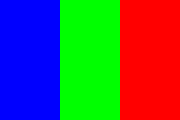

正確RGB


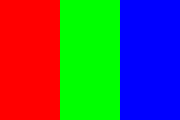

In [5]:
print("未轉換，紅藍會交換")
display(Image.fromarray(bgr))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("正確RGB")
display(Image.fromarray(rgb))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

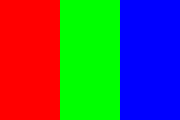

In [6]:
correct_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
assert correct_rgb[0, 0].tolist() == [255, 0, 0]
display(Image.fromarray(correct_rgb))

**參考答案與驗收**：轉成RGB後的圖符合指定顏色；shape維持(120,180,3)。

## W4-05 休息與畫面確認

060–070 分鐘，10分鐘。

- 休息10分鐘
- 確認左紅中綠右藍
- 存檔再離開座位

**操作任務**：存檔與休息。

**參考答案與驗收**：保留正確色塊輸出。

## W4-06 剪裁與複製

070–090 分鐘，20分鐘。

- img[y1:y2, x1:x2]
- 切片不含結束位置
- copy 避免修改原圖

**操作任務**：剪裁所有列、欄60到120，確認全綠且寬60。

(120, 60, 3)


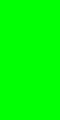

In [7]:
crop = rgb[:, 60:120].copy()
print(crop.shape)
display(Image.fromarray(crop))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

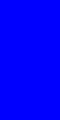

In [8]:
blue_crop = rgb[:, 120:180].copy()
assert blue_crop.shape == (120, 60, 3)
assert blue_crop[0, 0].tolist() == [0, 0, 255]
display(Image.fromarray(blue_crop))

**參考答案與驗收**：shape=(120,60,3)，RGB像素[0,255,0]。

## W4-07 縮放與灰階

090–110 分鐘，20分鐘。

- resize 尺寸參數先寬後高
- 灰階影像常是二維陣列
- 灰階值不是簡單取某一通道

**操作任務**：縮成寬90高60，再轉灰階，記錄兩個shape。

(60, 90, 3) (60, 90)


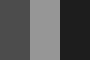

In [9]:
small_bgr = cv2.resize(bgr, (90, 60))
gray = cv2.cvtColor(small_bgr, cv2.COLOR_BGR2GRAY)
print(small_bgr.shape, gray.shape)
display(Image.fromarray(gray))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [10]:
small = cv2.resize(bgr, (60, 40))
assert small.shape == (40, 60, 3)
print(small.shape)

(40, 60, 3)


**參考答案與驗收**：彩色(60,90,3)，灰階(60,90)。

## W4-08 檔案讀寫與路徑

110–125 分鐘，15分鐘。

- 寫檔後確認成功
- 讀檔失敗會得到None
- 中文路徑可用位元組解碼

**操作任務**：儲存color_blocks.png再讀回，比對shape與像素。

In [11]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
image_path = output_dir / "color_blocks.png"
ok, encoded = cv2.imencode(".png", bgr)
if not ok:
    raise RuntimeError("PNG編碼失敗")
image_path.write_bytes(encoded.tobytes())
loaded = cv2.imdecode(np.frombuffer(image_path.read_bytes(), dtype=np.uint8), cv2.IMREAD_COLOR)
if loaded is None:
    raise ValueError("無法讀取影像")
print(loaded.shape, np.array_equal(loaded, bgr))

(120, 180, 3) True


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [12]:
assert image_path.exists()
assert np.array_equal(loaded, bgr)
print("讀寫一致")

讀寫一致


**參考答案與驗收**：解碼成功，shape及像素與原bgr相同。

## W4-09 閾值與規則處理

125–140 分鐘，15分鐘。

- threshold 依亮度切成黑白
- 門檻由人指定
- 影像處理不等於已訓練AI

**操作任務**：比較門檻50、120、200；用np.unique檢查黑白值。

[  0 255]


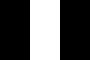

In [13]:
_, binary = cv2.threshold(gray, 120, 255, cv2.THRESH_BINARY)
print(np.unique(binary))
display(Image.fromarray(binary))

### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

In [14]:
_, binary_200 = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
assert np.count_nonzero(binary_200) <= np.count_nonzero(binary)
print(np.count_nonzero(binary_200))

0


**參考答案與驗收**：輸出值只可能0或255；門檻越高，白色像素不會增加。

## W4-10 本週實作 影像處理函數

140–160 分鐘，20分鐘。

- 函數接收BGR影像
- 縮放、灰階、二值化
- 回傳結果並保存

**操作任務**：完成preprocess；保存binary.png，測試門檻120與200。

In [15]:
print("本週專題：請完成下方函數")

本週專題：請完成下方函數


### 練習
先在下方寫出預測，再取消程式註解並完成。

預測：＿＿＿＿

執行後發現：＿＿＿＿

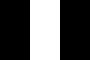

In [16]:
def preprocess(image_bgr, threshold_value=120):
    resized = cv2.resize(image_bgr, (90, 60))
    gray_image = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    _, result = cv2.threshold(gray_image, threshold_value, 255, cv2.THRESH_BINARY)
    return result

result = preprocess(bgr)
assert result.shape == (60, 90)
assert set(np.unique(result)).issubset({0, 255})
Image.fromarray(result).save(output_dir / "binary.png")
display(Image.fromarray(result))
assert np.count_nonzero(preprocess(bgr, 200)) <= np.count_nonzero(result)

**參考答案與驗收**：兩者shape=(60,90)，像素只含0或255；讀回binary.png應成功。

## W4-11 影像檢核與除錯

160–170 分鐘，10分鐘。

- 顏色以已知像素驗證
- 尺寸用shape驗證
- 裁切空陣列先檢查範圍

**操作任務**：同桌檢查色塊方向、函數輸出shape與保存檔案。

**參考答案與驗收**：左紅中綠右藍；黑白圖(60,90)；outputs/binary.png存在。

## W4-12 離堂題與課後練習

170–180 分鐘，10分鐘。

- shape 與 resize 的順序
- RGB 與 BGR 的差別
- 下週從資料建立分類器

**操作任務**：使用自製色塊圖測試流程並記錄shape，避免使用人臉或個資照片。

**參考答案與驗收**：shape高120寬180通道3；resize寬90高60；閾值由人指定。

## 課後作業參考解
以下為獨立解答，請在學員完成作業後提供。

(60, 90)


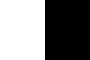

In [17]:
custom_bgr = np.zeros((40, 60, 3), dtype=np.uint8)
custom_bgr[:, :30] = [0, 255, 0]
custom_result = preprocess(custom_bgr)
print(custom_result.shape)
display(Image.fromarray(custom_result))